# Lesson 3: A neural network from scratch

A polynomial adds up a fixed list of functions (1, x, x² and so on) and only adjusts how much of each it uses. A neural network also adds up simple functions, but it adjusts the functions themselves: where each one switches, how steeply, and along which direction in input space. That is why it can follow a cliff in one corner without wiggling everywhere else.

Everything in this lesson is plain NumPy, in `emulator/numpy_mlp.py`, which is worth reading next to this notebook.

1. One hidden layer in one dimension
2. The network for our data
3. The loss
4. Backpropagation, and how to check it
5. Gradient descent
6. The learning rate

In [1]:
# 1. Let Python find the emulator package
import sys

sys.path.insert(0, "..")

# 2. Imports
import inspect
import json
import time

import matplotlib.pyplot as plt
import numpy as np

from emulator import data, evaluate, numpy_mlp
from emulator.evaluate import CONTEXT_GREY, PALETTE

## 1. One hidden layer in one dimension

Take one input x and one output y, with a hidden layer of *n* units in between. Each unit computes tanh(w x + b): a smooth step whose position is set by -b/w and whose steepness is set by w. The output adds the units up with weights v and an offset c, and training adjusts all of w, b, v and c:

$$ y(x) = c + \sum_{j=1}^{n} v_j \tanh(w_j x + b_j) $$

Below is a toy curve with the two features we saw in Lesson 1: a small step (like carbon moving between CH4 and CO) and a steep cliff onto a floor (like a condensing species).

In [2]:
# 1. The toy curve: a small step near x = 0.5 and a cliff onto a floor for x < 0
x_toy = np.linspace(-1, 1, 400)[:, None]
step = -1.5 / (1.0 + np.exp(-(x_toy - 0.5) / 0.04))
y_toy = np.where(x_toy > 0.0, -3.5 + step, -3.5 + 40.0 * x_toy)
y_toy = np.maximum(y_toy, -30.0)

# 2. Standardize it, as we do for the real outputs
toy_mean, toy_std = y_toy.mean(), y_toy.std()
y_toy_scaled = (y_toy - toy_mean) / toy_std

# 3. Fit networks with 1, 3 and 30 hidden units
toy_fits = {}
for n_units in [1, 3, 30]:
    params = numpy_mlp.init_params([1, n_units, 1], seed=1)
    params, history = numpy_mlp.train_sgd(
        params,
        x_toy,
        y_toy_scaled,
        x_toy,
        y_toy_scaled,
        learning_rate=0.1,
        batch_size=20,
        n_epochs=10000,
    )
    toy_fits[n_units] = params
    print(f"{n_units:2d} units: final loss {history['train_loss'][-1]:.1e}")

 1 units: final loss 6.6e-03


 3 units: final loss 1.6e-03


30 units: final loss 5.2e-04


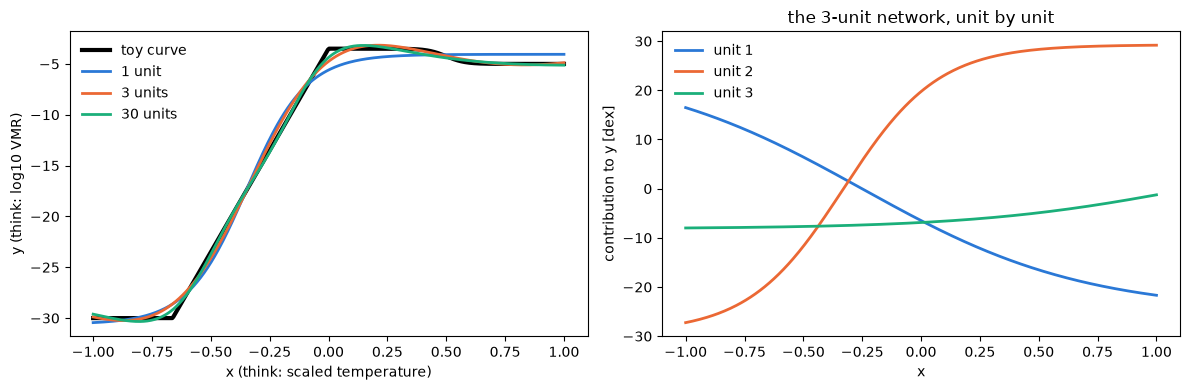

In [3]:
# 1. Data and the three fits
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x_toy, y_toy, color="black", lw=3, label="toy curve")
for colour, (n_units, params) in zip(PALETTE, toy_fits.items()):
    fit = numpy_mlp.forward(params, x_toy)[0] * toy_std + toy_mean
    axes[0].plot(
        x_toy,
        fit,
        color=colour,
        lw=2,
        label=f"{n_units} unit" + ("s" if n_units > 1 else ""),
    )
axes[0].set(xlabel="x (think: scaled temperature)", ylabel="y (think: log10 VMR)")
axes[0].legend(frameon=False)

# 2. The 3-unit network taken apart: each unit's contribution v_j tanh(w_j x + b_j)
params = toy_fits[3]
hidden = np.tanh(x_toy @ params[0]["W"] + params[0]["b"])
for unit in range(3):
    contribution = hidden[:, unit] * params[1]["W"][unit, 0] * toy_std
    axes[1].plot(
        x_toy, contribution, color=PALETTE[unit], lw=2, label=f"unit {unit + 1}"
    )
axes[1].set(
    xlabel="x",
    ylabel="contribution to y [dex]",
    title="the 3-unit network, unit by unit",
)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

One unit can make one step, so it spends itself on the cliff (the biggest feature) and misses the small step near x = 0.5. Three units get both, and thirty make the corners sharper.

The right panel takes the 3-unit network apart. The units do not split the work the way you would by hand: two of them are large and partly cancel each other, and only their sum has the right shape. Many different sets of weights give nearly the same curve, and training only has to find one of them, so individual units need not mean anything physical.

**A network is a sum of adjustable steps, and with enough of them it can approximate any reasonable function** (the *universal approximation theorem*).

With several inputs each unit becomes tanh(w · x + b): a step across a plane in input space, oriented along w. Stacking layers lets later units build steps out of earlier steps, which is a more economical way to make complicated shapes.

## 2. The network for our data

For six inputs and 19 outputs, with two hidden layers of 64 units:

$$ a_1 = \tanh(x W_1 + b_1), \quad a_2 = \tanh(a_1 W_2 + b_2), \quad y = a_2 W_3 + b_3 $$

Each row of x is one model, W₁ is 6×64, W₂ is 64×64 and W₃ is 64×19, and the output layer has no tanh so that outputs can take any value.

In [4]:
# 1. Load and transform the data (as in Lessons 1 and 2)
grid = data.load_grid("../training_250k.h5")
inputs, outputs, output_names = grid["inputs"], grid["outputs"], grid["output_names"]
indices = data.split_from_labels(grid["split"])
train, val = indices["train"], indices["val"]
input_transform = data.fit_input_transform(inputs[train])
output_transform = data.fit_output_transform(outputs[train])
x_train = data.transform_inputs(inputs[train], input_transform)
x_val = data.transform_inputs(inputs[val], input_transform)
y_train = data.transform_outputs(outputs[train], output_transform)
y_val = data.transform_outputs(outputs[val], output_transform)

# 2. A network with random weights
layer_sizes = [6, 64, 64, 19]
params = numpy_mlp.init_params(layer_sizes, seed=0)
for number, layer in enumerate(params, start=1):
    print(f"layer {number}: W {layer['W'].shape}, b {layer['b'].shape}")
print("trainable numbers:", numpy_mlp.count_params(params))

layer 1: W (6, 64), b (64,)
layer 2: W (64, 64), b (64,)
layer 3: W (64, 19), b (19,)
trainable numbers: 5843


About 5,800 numbers to describe 200,000 models × 19 outputs = 3.8 million values. The weights start random (`init_params` explains why they are drawn with a spread of 1/√(inputs to the layer)), so before training the predictions are noise:

In [5]:
y_pred, _ = numpy_mlp.forward(params, x_val)
print("loss with random weights:", numpy_mlp.mean_squared_error(y_pred, y_val))

loss with random weights: 1.1414812903389644


A loss near 1 means errors as large as the spread of the data itself (the outputs are standardized), no better than predicting the mean.

## 3. The loss

Training needs one number that says how wrong the network is. We use the **mean squared error** over all models and outputs in standardized units:

$$ L = \frac{1}{N K} \sum_{i=1}^{N} \sum_{k=1}^{K} \left(y^{\rm pred}_{ik} - y^{\rm true}_{ik}\right)^2 $$

This is a familiar object: up to a constant, it is minus the log-likelihood of Gaussian errors with the same σ for every output (σ = 1 in standardized units). **Training a network is maximum-likelihood fitting**, with thousands of parameters instead of a handful, and with no closed-form solution because the model is not linear in its parameters.

## 4. Backpropagation

To lower the loss we need its gradient: how L changes when each weight changes. Backpropagation is the chain rule applied layer by layer, starting from the output. Write z = a W + b for a layer's value before the tanh and δ = ∂L/∂z. Then:

1. At the output (no tanh): $\delta_3 = \frac{2}{NK} (y^{\rm pred} - y^{\rm true})$
2. For any layer with input a: $\partial L/\partial W = a^{\rm T} \delta$ and $\partial L/\partial b = \sum_{\rm models} \delta$
3. Passing back through W and the tanh: $\delta_{\rm previous} = (\delta W^{\rm T}) \odot (1 - a^2)$, using $\frac{d}{dz}\tanh z = 1 - \tanh^2 z$

Here is the code that does it:

In [6]:
print(inspect.getsource(numpy_mlp.backward))

def backward(
    params,
    activations,
    y_pred,
    y_true,
):
    """Gradient of the mean squared error with respect to every parameter.

    Parameters
    ----------
    params : list of dict
        Network weights used in the forward pass.
    activations : list of ndarray
        Second output of ``forward`` (the input to every layer).
    y_pred : ndarray, shape (n_batch, n_outputs)
        First output of ``forward``.
    y_true : ndarray, shape (n_batch, n_outputs)
        Target outputs.

    Returns
    -------
    grads : list of dict
        Same structure as ``params``: ``grads[l]["W"]`` is dLoss/dW_l and
        ``grads[l]["b"]`` is dLoss/db_l.

    Notes
    -----
    ``delta`` (shape (n_batch, n_units)) holds dLoss/dz for the current
    layer, where z = a @ W + b is the layer's value before the tanh. The
    chain rule gives, going from the last layer to the first:

    - output layer: delta = 2 (y_pred - y_true) / (n_batch * n_outputs)
    - weights:      dLos

Hand-written gradients are easy to get wrong, so we test them against finite differences: nudge each weight up and down by 1e-6 and measure the change in the loss. That costs two forward passes per weight, so we use a tiny network (6, 5, 4 and 19 units, 154 weights).

In [7]:
# 1. A tiny network and a few models
small_params = numpy_mlp.init_params([6, 5, 4, 19], seed=3)
x_small, y_small = x_train[:10], y_train[:10]

# 2. Gradients by backpropagation and by finite differences
y_pred, activations = numpy_mlp.forward(small_params, x_small)
backprop = numpy_mlp.backward(small_params, activations, y_pred, y_small)
finite = numpy_mlp.numerical_gradient(small_params, x_small, y_small)

# 3. Largest relative difference, array by array
for number, (exact, approx) in enumerate(zip(backprop, finite), start=1):
    for key in ("W", "b"):
        relative = np.abs(exact[key] - approx[key]).max() / np.abs(approx[key]).max()
        print(f"layer {number} {key}: relative difference {relative:.1e}")

layer 1 W: relative difference 1.7e-09
layer 1 b: relative difference 4.9e-09
layer 2 W: relative difference 1.5e-09
layer 2 b: relative difference 2.3e-09
layer 3 W: relative difference 3.1e-09
layer 3 b: relative difference 2.9e-09


Agreement to about 1e-9: the backward pass is right. (In Lesson 4 JAX computes these gradients automatically, and we will check it against this function too.)

## 5. Gradient descent

With the gradient in hand, take a small step downhill and repeat:

$$ \theta \leftarrow \theta - \eta \, \frac{\partial L}{\partial \theta} $$

where η is the *learning rate*. Computing the gradient on all 200,000 models for every step would be slow, so each step uses a random *mini-batch* of 256 models. The batch gradient is a noisy but unbiased estimate of the full one, and we get 780 steps per pass through the data instead of one. A full pass through the data is an *epoch*, and the whole procedure is called *stochastic gradient descent* (SGD).

10 s


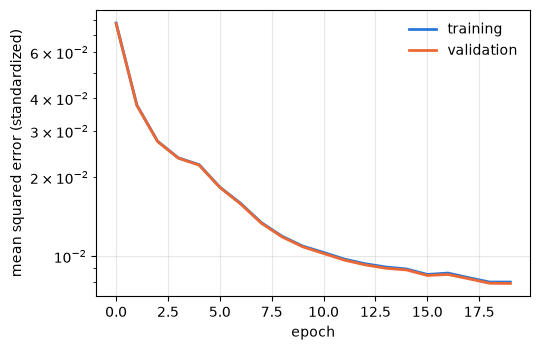

In [8]:
# 1. Train for 20 epochs with SGD
start = time.perf_counter()
params = numpy_mlp.init_params(layer_sizes, seed=0)
params, history = numpy_mlp.train_sgd(
    params,
    x_train,
    y_train,
    x_val,
    y_val,
    learning_rate=0.3,
    batch_size=256,
    n_epochs=20,
)
print(f"{time.perf_counter() - start:.0f} s")

# 2. Loss curves
fig = evaluate.plot_history(history)
plt.show()

In [9]:
# 1. Errors in dex on the validation set
y_pred, _ = numpy_mlp.forward(params, x_val)
log10_pred = data.inverse_transform_outputs(y_pred, output_transform)
numpy_scores = evaluate.summary_errors(outputs[val], log10_pred)

# 2. Compare with Lesson 2
with open("../runs/baseline_scores.json") as handle:
    scores = json.load(handle)
scores["NumPy network, SGD, 20 epochs"] = numpy_scores
for name, score in scores.items():
    print(f"{name:30s} median {score['median']:.4f} dex   99% {score['p99']:.3f} dex")

mean                           median 9.5135 dex   99% 15.398 dex
polynomial, degree 1           median 3.3587 dex   99% 8.094 dex
polynomial, degree 2           median 2.5986 dex   99% 7.081 dex
polynomial, degree 3           median 1.4586 dex   99% 4.636 dex
polynomial, degree 4           median 0.9077 dex   99% 3.619 dex
polynomial, degree 5           median 0.7193 dex   99% 3.029 dex
nearest neighbours, k=1        median 0.3736 dex   99% 5.694 dex
nearest neighbours, k=8        median 0.2910 dex   99% 3.008 dex
nearest neighbours, k=32       median 0.3979 dex   99% 2.900 dex
NumPy network, SGD, 20 epochs  median 0.2873 dex   99% 1.924 dex


A network with 5,843 numbers, trained for 20 epochs with plain SGD in a few seconds, already matches nearest neighbours on the typical error and beats every baseline on the bad cases (the 99% column). Nearest neighbours needs the whole training table at prediction time, and the best polynomial uses 462 × 19 = 8,778 coefficients. And the loss curve is still falling, so the network is not done learning. Lesson 4 makes training much faster.

## 6. The learning rate

The learning rate is the most important setting in training. With too small a rate the loss creeps down, and with too large a rate each step jumps across the valley instead of down it, so the loss stalls and bounces.

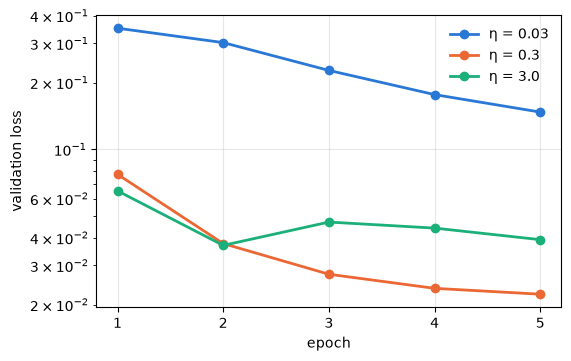

In [10]:
# 1. Five epochs at three learning rates, from the same starting weights
fig, ax = plt.subplots(figsize=(6, 3.8))
for colour, learning_rate in zip(PALETTE, [0.03, 0.3, 3.0]):
    params = numpy_mlp.init_params(layer_sizes, seed=0)
    _, history = numpy_mlp.train_sgd(
        params,
        x_train,
        y_train,
        x_val,
        y_val,
        learning_rate=learning_rate,
        batch_size=256,
        n_epochs=5,
    )
    ax.plot(
        np.arange(1, 6),
        history["val_loss"],
        "o-",
        color=colour,
        lw=2,
        label=f"η = {learning_rate}",
    )
ax.set(xlabel="epoch", ylabel="validation loss", yscale="log")
ax.set_xticks(range(1, 6))
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

## Exercises

1. Make the hidden layers 16 or 128 units wide. How do training time and validation error change?
2. Train for 100 epochs instead of 20. Does the validation loss ever start rising again (overfitting)?
3. Replace tanh by ReLU, max(0, z). You need to change two lines in `numpy_mlp.py`: the activation in `forward` and its derivative in `backward` (the derivative of ReLU is 1 where z > 0 and 0 elsewhere). Run the gradient check before training.
4. Add momentum to `train_sgd`: keep a running velocity v ← 0.9 v - η g and update θ ← θ + v. Does it train faster?